In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
from sklearn.pipeline import Pipeline


In [2]:
df=pd.read_csv('/content/HR.csv')

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [5]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [6]:
df.shape

(1470, 35)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [8]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


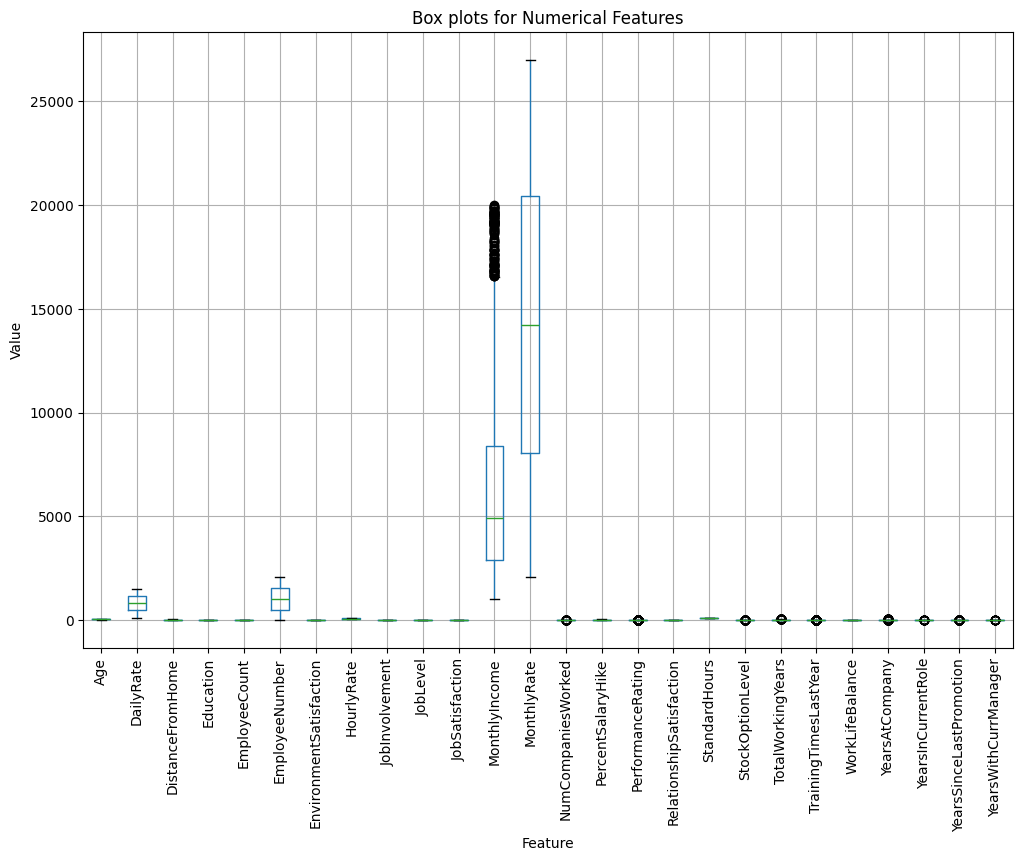

In [9]:

numerical_cols = df.select_dtypes(include=['int', 'float']).columns

plt.figure(figsize=(12, 8))
df[numerical_cols].boxplot()
plt.xticks(rotation=90)
plt.title('Box plots for Numerical Features')
plt.ylabel('Value')
plt.xlabel('Feature')
plt.show()

<Axes: >

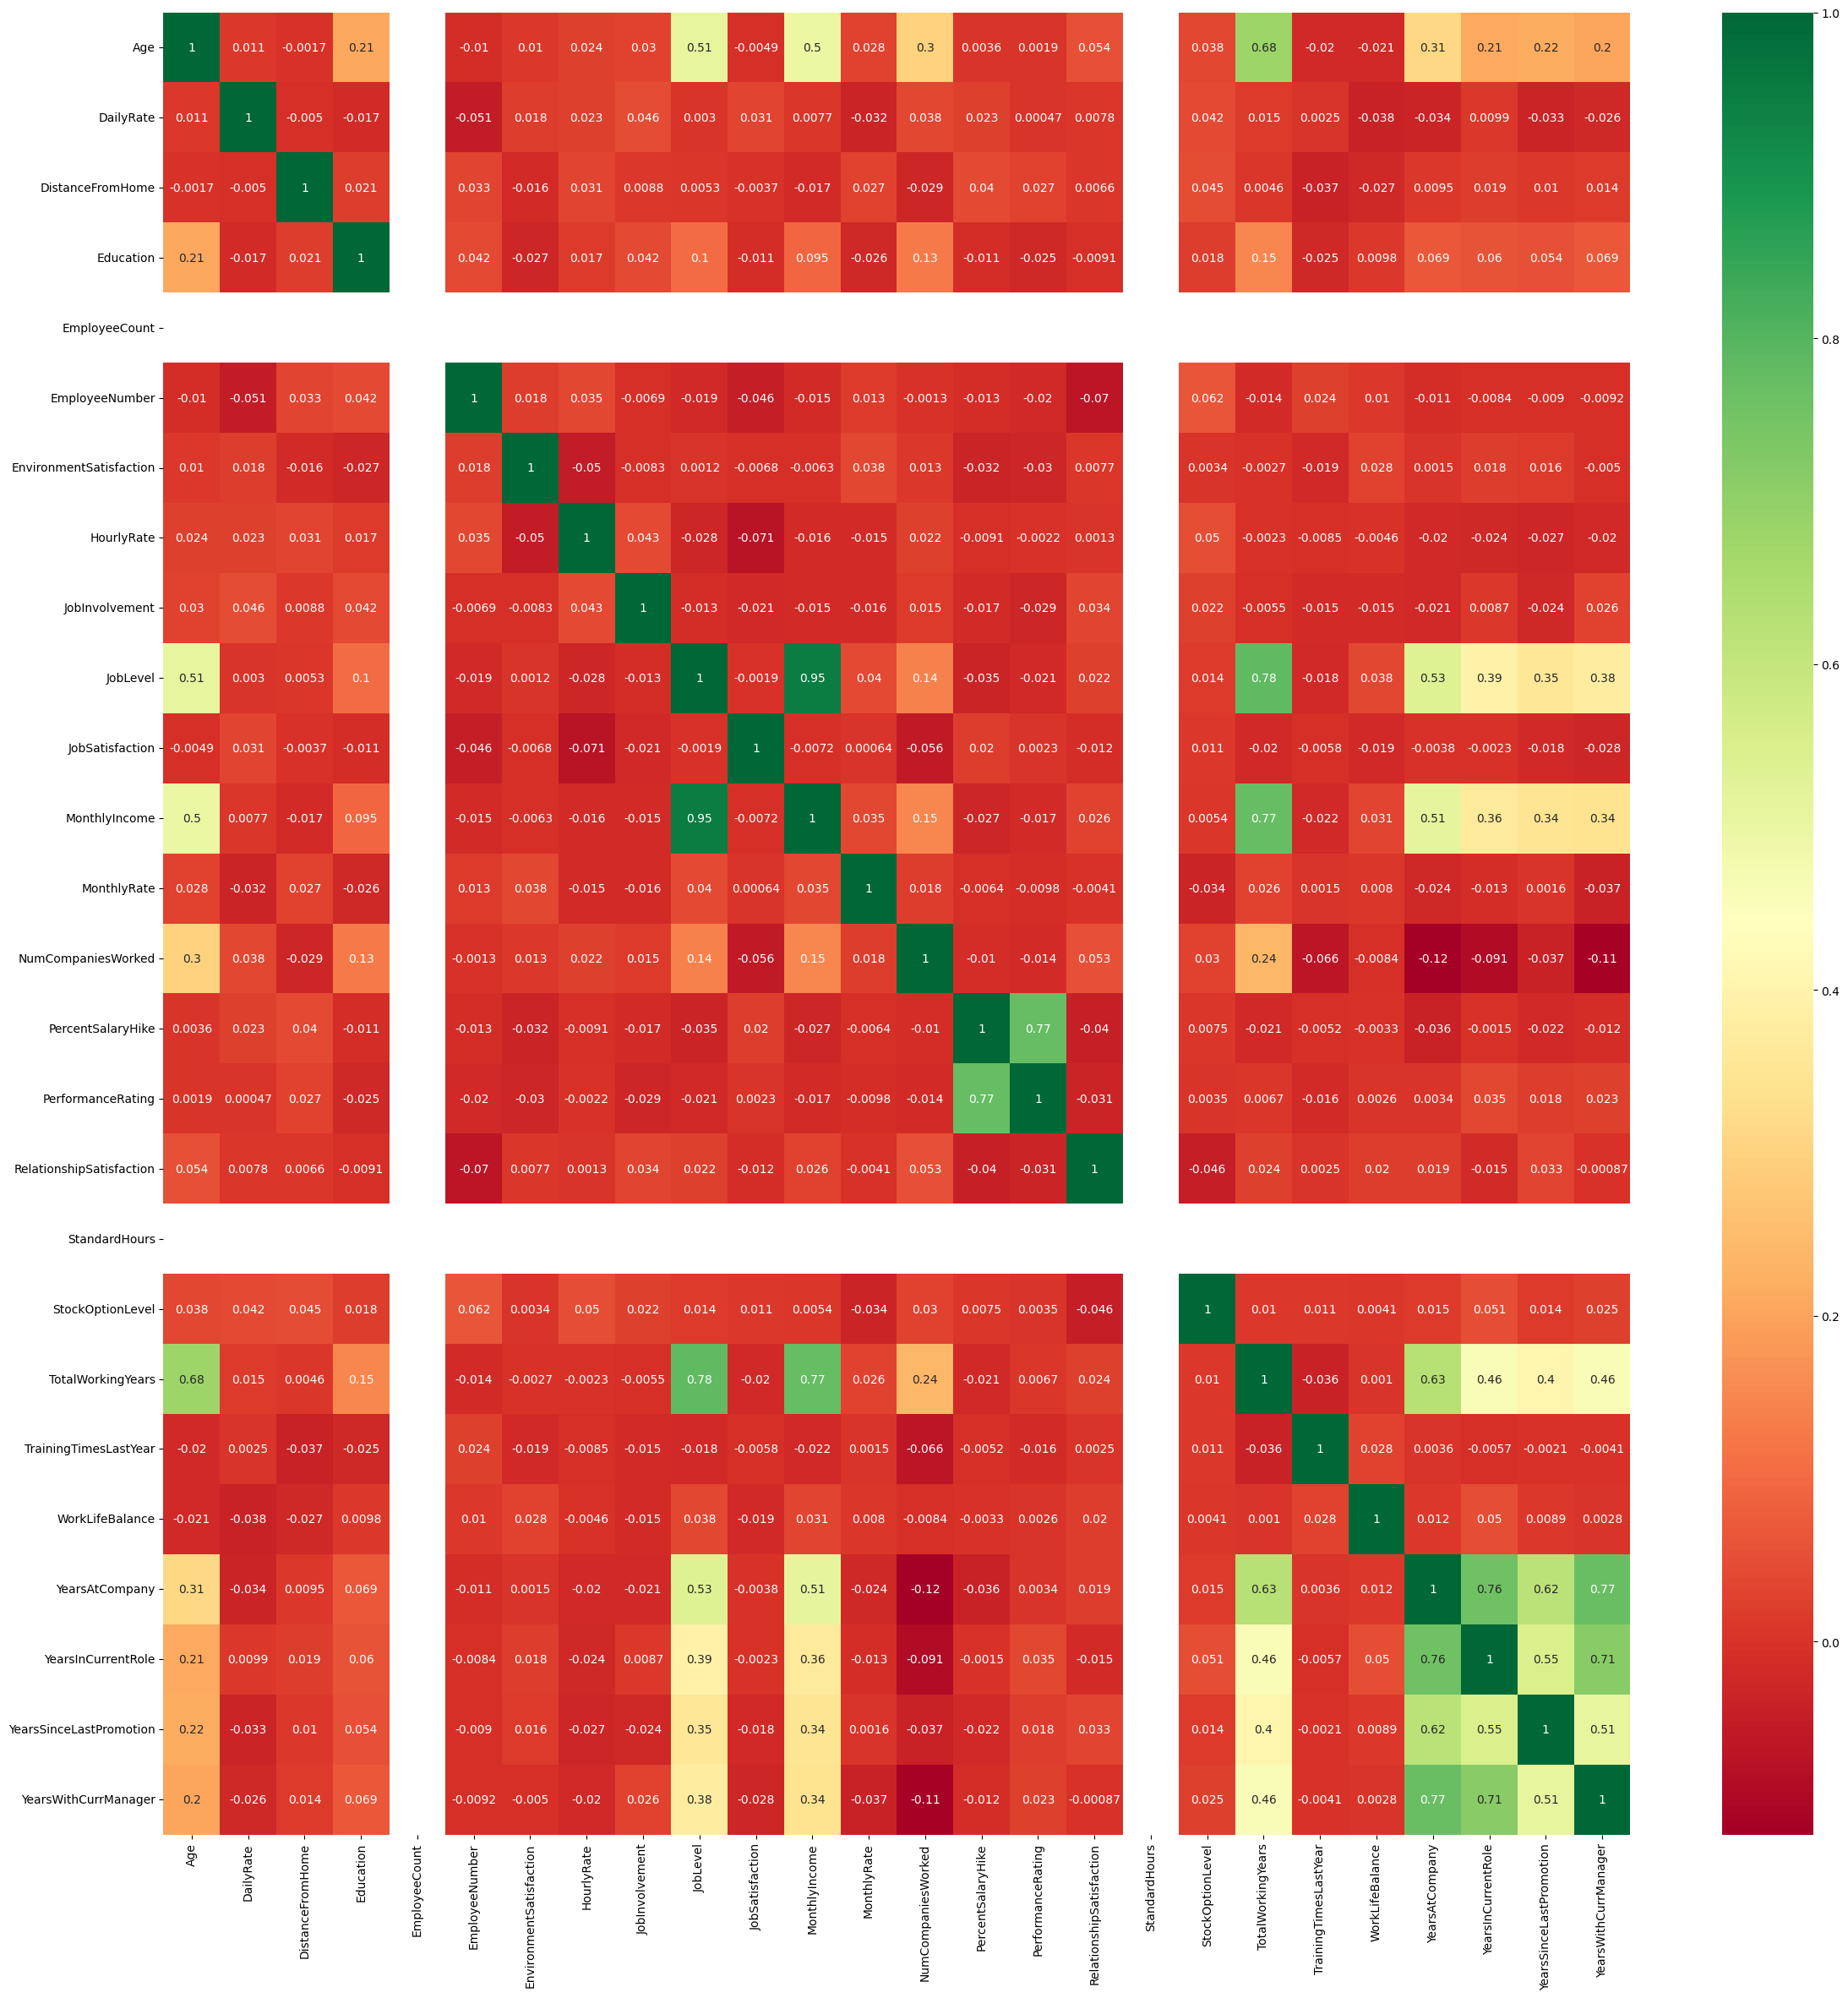

In [10]:
plt.figure(figsize=(28,28))#increase plot size
sns.heatmap(df.select_dtypes(include=['int', 'float']).corr(),cmap="RdYlGn",annot=True)

In [11]:
df.BusinessTravel.value_counts()

,count
BusinessTravel,
Travel_Rarely,1043
Travel_Frequently,277
Non-Travel,150


In [12]:
df.Department.value_counts()

,count
Department,
Research & Development,961
Sales,446
Human Resources,63


In [13]:
df.Education.value_counts()

,count
Education,
3,572
4,398
2,282
1,170
5,48


In [14]:
df.EnvironmentSatisfaction.value_counts()

,count
EnvironmentSatisfaction,
3,453
4,446
2,287
1,284


In [15]:
df.Gender.value_counts()

,count
Gender,
Male,882
Female,588


In [16]:
df.JobInvolvement.value_counts()

,count
JobInvolvement,
3,868
2,375
4,144
1,83


In [17]:
df.Attrition.value_counts()

,count
Attrition,
No,1233
Yes,237


In [18]:
df.JobLevel.value_counts()

,count
JobLevel,
1,543
2,534
3,218
4,106
5,69


In [19]:
df.JobRole.value_counts()

,count
JobRole,
Sales Executive,326
Research Scientist,292
Laboratory Technician,259
Manufacturing Director,145
Healthcare Representative,131
Manager,102
Sales Representative,83
Research Director,80
Human Resources,52


In [20]:
df.JobSatisfaction.value_counts()

,count
JobSatisfaction,
4,459
3,442
1,289
2,280


In [21]:
df.MaritalStatus.value_counts()

,count
MaritalStatus,
Married,673
Single,470
Divorced,327


In [24]:
df.OverTime.value_counts()

,count
OverTime,
No,1054
Yes,416


In [25]:
df.PerformanceRating.value_counts()

,count
PerformanceRating,
3,1244
4,226


In [26]:
df.RelationshipSatisfaction.value_counts()

,count
RelationshipSatisfaction,
3,459
4,432
2,303
1,276


In [27]:
df.RelationshipSatisfaction.value_counts()

,count
RelationshipSatisfaction,
3,459
4,432
2,303
1,276


In [28]:
df.StockOptionLevel.value_counts()

,count
StockOptionLevel,
0,631
1,596
2,158
3,85


In [29]:
df.TrainingTimesLastYear.value_counts()

,count
TrainingTimesLastYear,
2,547
3,491
4,123
5,119
1,71
6,65
0,54


In [30]:
df.WorkLifeBalance.value_counts()

,count
WorkLifeBalance,
3,893
2,344
4,153
1,80


In [31]:
OHE_columns=['BusinessTravel','Department','MaritalStatus','EducationField','Gender','JobRole']
standard_scaler=['Age', 'DailyRate', 'DistanceFromHome','MonthlyRate', 'HourlyRate', 'NumCompaniesWorked', 'TotalWorkingYears',
                 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager','PercentSalaryHike']
label_encoder=['OverTime']
passthrough=['Education','EnvironmentSatisfaction','JobInvolvement','JobLevel','JobSatisfaction','PercentSalaryHike','RelationshipSatisfaction',
             'StockOptionLevel','TrainingTimesLastYear','WorkLifeBalance','PerformanceRating']

In [32]:
class ModifiedLabelEncoder(LabelEncoder):
    def fit_transform(self, y, *args, **kwargs):
        return super().fit_transform(y).reshape(-1, 1)

    def transform(self, y, *args, **kwargs):
        return super().transform(y).reshape(-1, 1)

In [33]:
def same(x):
    return x

In [34]:
no_trans=FunctionTransformer(same)

In [35]:
preprocessor = ColumnTransformer([
    ("OHE columns", OneHotEncoder(), OHE_columns),
    ("Label_encoder", ModifiedLabelEncoder(), label_encoder),
    ("Standard_scaler", StandardScaler(), standard_scaler),
    ('Pass_through',no_trans,passthrough)])

In [36]:
preprocessor

ColumnTransformer(transformers=[('OHE columns', OneHotEncoder(),
                                 ['BusinessTravel', 'Department',
                                  'MaritalStatus', 'EducationField', 'Gender',
                                  'JobRole']),
                                ('Label_encoder', ModifiedLabelEncoder(),
                                 ['OverTime']),
                                ('Standard_scaler', StandardScaler(),
                                 ['Age', 'DailyRate', 'DistanceFromHome',
                                  'MonthlyRate', 'HourlyRate',
                                  'NumCompaniesWorked', 'TotalWorkingYears',
                                  'Traini...
                                  'YearsSinceLastPromotion',
                                  'YearsWithCurrManager',
                                  'PercentSalaryHike']),
                                ('Pass_through',
                                 FunctionTransformer(func=<function same at 0x7a7334a0ede0>),
                                 ['Education', 'EnvironmentSatisfaction',
                                  'JobInvolvement', 'JobLevel',
                                  'JobSatisfaction', 'PercentSalaryHike',
                                  'RelationshipSatisfaction',
                                  'StockOptionLevel', 'TrainingTimesLastYear',
                                  'WorkLifeBalance', 'PerformanceRating'])])

In [37]:
import pickle

with open("rfpickle.pkl", "wb") as f:
    pickle.dump(preprocessor, f)